<a href="https://colab.research.google.com/github/mshmatsuda/machine-learning-green-book/blob/main/01_01_%E6%95%99%E5%B8%AB%E3%81%82%E3%82%8A%E5%AD%A6%E7%BF%92.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

第2章「教師あり学習」では、まずk-近傍法で使用する2クラス分類用のシンプルなforgeデータセットを読み込み、散布図としてプロットしてデータの配置を確認します。<br>
<br>
コードを実行すると26個のデータと2つの特徴量を持つデータセットが視覚化され、次のステップで近傍の数を変更した際的模型の境界線の変化を確認する準備が整います。


## 00_準備

In [1]:
# 書籍用のライブラリをインストール
!pip install mglearn

# 基本ライブラリのインポート
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import mglearn
import sklearn

# Colabでグラフを綺麗にインライン表示するための設定
%matplotlib inline


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 581.4/581.4 kB 10.7 MB/s  0:00:00


## 01_データの読み込み／データの確認①

X shape: (26, 2)


Text(0, 0.5, 'Second feature')

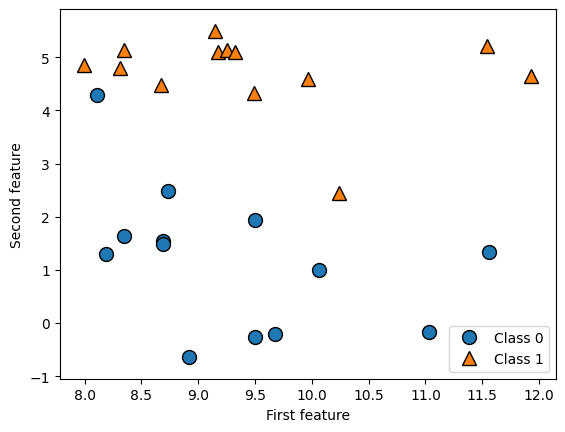

In [2]:
# 2章用の実験データを生成
X, y = mglearn.datasets.make_forge()

# データの形（Shape）を確認
print("X shape:", X.shape)

# 散布図を描画してデータをビジュアルで観察する
mglearn.discrete_scatter(X[:, 0], X[:, 1], y)
plt.legend(["Class 0", "Class 1"], loc=4)
plt.xlabel("First feature")
plt.ylabel("Second feature")


まずはステップ①「概念」とステップ②「ビジュアル」を同時に掴むために、2章で最初に使うシンプルな実験用データ「forge（フォージ）データセット」を読み込んで、グラフに描画します。<br>
<br>

## 💡 このコードは何をしているの？（ステップ①：概念）

* make_forge():
  * アヤメのデータよりもさらにシンプルな、「2つの特徴量（2次元）」と「2つのクラス（丸と三角）」で構成された、本書オリジナルのデモ用データです。
* X.shape:
  * 実行すると (26, 2) と表示されます。
  * 今回は「26個のデータ（点）があり、それぞれ2つの特徴量（横軸と縦軸の数値）を持っている」という状態です。

## 🎨 画面のグラフを見てみましょう（ステップ②：ビジュアル）

実行すると、画面に丸（Class 0）と三角（Class 1）のデータが散らばった散布図が表示されます。<br><br>
あなたの「鉄板イメージ」を重ねてみてください。<br>
このグラフは、まだ水を注いでいない、フラットな鉄板の上に丸と三角のピンが刺さっている状態です。<br>
次はこの鉄板の上に、k-近傍法（k-NN）を使って「海と陸の境界線」を作っていきます！
<br><br>
まずはこのデータが無事に表示されたか確認しましょう。<br><br>
画面に丸と三角が散らばった散布図グラフは無事に表示されましたか？<br><br>
確認できたら、次はいよいよご近所さんの数（n_neighbors）を変えて、「鉄板の凸凹（境界線）がどう変化するか」を一気に描き出すコード（ステップ③）へ進みます！準備はいいですか？


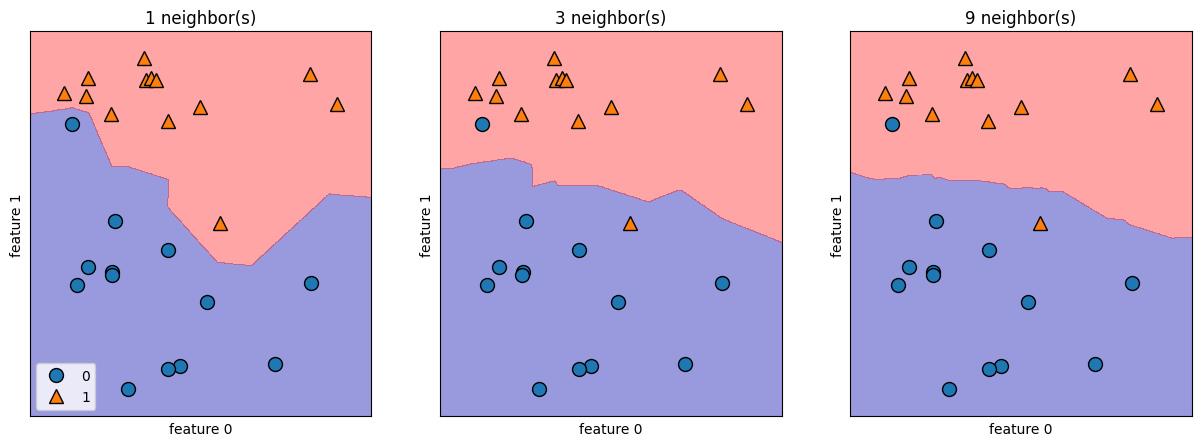

In [4]:
# 今回は sklearn.neighbors から KNeighborsClassifier をインポートするコードを追加
from sklearn.neighbors import KNeighborsClassifier

# 1個、3個、9個の近傍点でそれぞれ境界線（決定境界）を描く
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for n_neighbors, ax in zip([1, 3, 9], axes):
    # モデルの定義と学習（ステップ③：コード）
    clf = KNeighborsClassifier(n_neighbors=n_neighbors).fit(X, y)

    # 境界線（海と陸の分かれ目）をプロット（ステップ②：ビジュアル）
    mglearn.plots.plot_2d_separator(clf, X, fill=True, eps=0.5, ax=ax, alpha=.4)
    mglearn.discrete_scatter(X[:, 0], X[:, 1], y, ax=ax)

    ax.set_title("{} neighbor(s)".format(n_neighbors))
    ax.set_xlabel("feature 0")
    ax.set_ylabel("feature 1")

axes[0].legend(loc=3)

それでは、第2章の最初のクライマックスです。<br><br>
k-近傍法において、ご近所さんの数（n_neighbors）を 「1人」「3人」「9人」 と増やしていったときに、鉄板の凸凹（海と陸の境界線）がどう変化するかを一気にビジュアル化してみましょう！<br><br>

## 🧠 表示された3つのグラフをイメージで読み解く

実行すると、左から「1人」「3人」「9人」の順で、オレンジ（陸）とブルー（海）に塗り分けられた3つのグラフが表示されます。<br><br>

ご自身の「鉄板イメージ」と照らし合わせてみてください。
* 左：1 neighbor（1人のとき）
  * 鉄板の状態：ピンの周りを細かくトントン叩きすぎて、境界線がガタガタ・ジグザグになっています。
  * 機械学習の用語：これが過学習（オーバーフィッティング）です。手元の訓練データ（過去問）を丸暗記しすぎているため、もしここに新しく変なピン（ノイズ）が1個でもあると、境界線がそれに引っ張られてしまい、本番のテストで間違えやすくなります。
* 右：9 neighbors（9人のとき）
  * 鉄板の状態：たくさんのご近所さんの多数決を取るため、細かい凸凹が無視されて、境界線がなめらかな直線（平らな鉄板）に近づいていきます。
  * 機械学習の用語：これを汎化（はんか）が進んだ状態、あるいは行き過ぎるとアンダーフィッティング（学習不足）と言います。細かな個性を無視してざっくり分けすぎると、今度は訓練データの正解率すら下がってしまいます。

<br>機械学習の目的は、このガタガタ（左）となめらか（右）の間の「ちょうどいい叩き具合（真ん中の3人のような状態）」をパラメータ調整で見つけ出すことです。<br><br>
画面にガタガタからなめらかに変化する3つの境界線グラフは表示されましたか？<br><br>
この「パラメータを変えると鉄板の形が変わる」という感覚が掴めたら、次は「本物のデータ（がんのデータ）を使って、この正解率のバランスを計算で確認する」ステップへ進みます。<br><br>準備ができたら教えてください！


## 質問1
ガタガタからなめらかに変化する３つの境界線グラフが表示されました。いまは概念理解とビジュアル化（何をやっているかイメージをもつ）をしているのはわかるのですが、機械学習モデルを構築するフェーズでいうと、「データを読み込む／確認」フェーズという理解でよいですか。

## 回答1
非常に鋭い視点ですが、フェーズの理解としては一歩先に進んでいます！<br><br>
機械学習のプロジェクト全体の中でいうと、今やっていることは「データの読み込み/確認」ではなく、「モデルの性質（特徴）をビジュアルで理解・分析している」フェーズになります。<br><br>
具体的に、先ほどのコードがどのフェーズにあたるのかを整理しました。

## 📊 プロジェクトの流れと現在の位置

1. データを読み込む／確認（前処理含む）
   * X, y = mglearn.datasets.make_forge() の1行目だけがここにあたります。
2. モデルの構築・学習（ここからが本番！）
   * コード内の clf = KNeighborsClassifier(...).fit(X, y) の部分です。ここでAIにデータを学習させてルール（モデル）を作っています。
3. モデルの評価・分析（★いまココ！）
   * plot_2d_separator(...) で境界線を描いた部分です。
   * 本来、実務ではグラフを毎回描くのではなく、第1章でやったように「テストデータの正解率（97%など）」という数字を見てモデルを評価します。
   * しかし、今は「アヤメ本」の第2章なので、「k-近傍法というアルゴリズムに、パラメータ（近所の人）を変えて学習（fit）させると、出来上がるルール（境界線）の形がどう変わるのか」という、アルゴリズムの癖や知能の形をビジュアルで分析・勉強している状態です。

## 💡 なぜ今、このフェーズをビジュアルでやっているの？

実際の仕事（実務）では、アヤメの4次元や、さらに多い100次元といった「人間の目には見えない高次元の鉄板」を扱うため、このように綺麗なグラフ（2次元）を描いて境界線を目視することはできません。<br><br>
だからこそ、今のうちに「2次元のシンプルなデータ（forge）」を使って、「パラメータ（n_neighbors）をいじると、AIの頭の中の鉄板（境界線）がガタガタになったり滑らかになったりするんだな」という仕組みのイメージを脳内にストックしているのです。<br><br>
このイメージさえあれば、今後グラフが見えない高次元のデータを扱うときも、「あ、今正解率が下がったのは、鉄板がガタガタ（過学習）になりすぎているからだな。じゃあ滑らかにするパラメータに変えよう」と、目に見えないAIの知能の形を頭の中で想像してコントロールできるようになります！<br><br>
今いる位置（モデルの性質をビジュアルで解剖しているフェーズ）のイメージはバッチリ繋がりましたでしょうか？<br><br>
この「ビジュアル理解」が完璧にできたので、次はいよいよステップ③「コード・計算理解」として、本物のデータ（医療系データ）を使い、「ガタガタと滑らかのバランスが、実際の正解率の数字にどう現れるか」をグラフ化して計算で確かめます。<br><br>準備ができたら教えてください！
